 # The central limit theorem and Monte Carlo Error

 This notebook explores one of the modt important theorems in statistics **Central Limit Theorem (CLT)** and its crucial role in understanding **Monte Carlo simulation error**.

# Setup: Import libraries

In [2]:
pip install seaborn

   ---------------------------------------- 0.0/9.8 MB ? eta -:--:--
   --------- ------------------------------ 2.4/9.8 MB 11.8 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.8 MB 11.8 MB/s eta 0:00:01
   ----------------------------- ---------- 7.3/9.8 MB 11.6 MB/s eta 0:00:01
   ---------------------------------------  9.7/9.8 MB 11.7 MB/s eta 0:00:01
   ---------------------------------------- 9.8/9.8 MB 10.8 MB/s  0:00:00

   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ---------------------------------------- 0/3 [tzdata]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- -------------------------- 1/3 [pandas]
   ------------- ------------------

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import norm
import warnings
warnings.filterwarnings("ignore")

# set style for beautiful plots
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
np.random.seed(42)

# configure plot aesthetics
plt.rcParams['figure.figsize'] = [12, 6]
plt.rcParams['font.size'] = 11
plt.rcParams['axes.labelsize'] = 14
plt.rcParams['axes.titlesize'] = 12

print("All libraries imported and configurations set successfully.")
print("Ready to perform statistical analysis and visualization.")

All libraries imported and configurations set successfully.
Ready to perform statistical analysis and visualization.


<a id="1. Introduction></a>
## 1. Introduction to the central limit theorem

### The theorem Statement
 > **Central Limit Theorem**: Let $X_1, X_2, \ldots, X_n$ be independent and identically distributed (i.i.d) random variables with mean $\mu$ and finite variance $\sigma^2$.
 Then, as $n \to \infty$:
 >
 > $$\frac{\bar{X}_n - \mu}{\sigma /\sqrt{n}} \xrightarrow{d} \mathcal{N}(0,1)$$
 >
 > Or equivalently : $\bar{X}_n \xrightarrow{d} \mathcal{N}\left(\mu, \frac{\sigma^2}{n}\right)$

 ### Intuitive Understanding

The CLT tells us something remarkable:

**No matter what distribution your data comes from**, if you:
1. Take many random samples of size $n$
2. Calculate the mean of each sample
3. Look at the distribution of those sample means

**The distribution of sample means will be approximately Normal!**

### Key Properties:
- The mean of sample means equal to the population mean: $E[\bar{X}] = \mu$
- The standard deviation of sample means (standard error): $SE = \frac{\sigma}{\sqrt{n}}$
- Larger samples -> narrower ditribution of sample means
- Works for ant distribution with finite variance

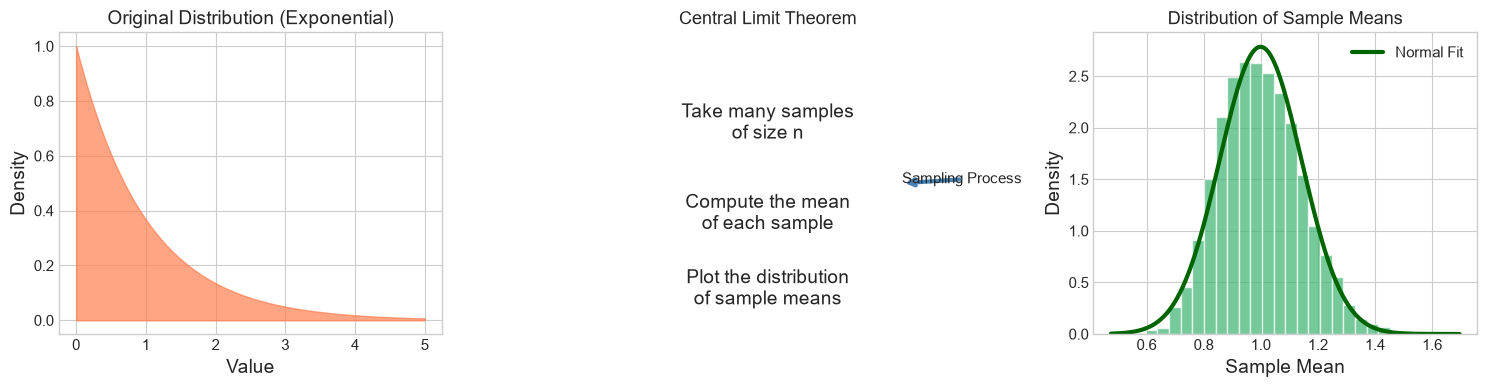

Central Limit Theorem visualization created and saved successfully!


In [5]:
# Visual: The CLT in one picture
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Original distribution (very non-normal)
x = np.linspace(0,5,1000)
original = stats.expon.pdf(x, scale=1)
axes[0].fill_between(x, original, color='coral', alpha=0.7)
axes[0].set_title('Original Distribution (Exponential)', fontsize=14)
axes[0].set_xlabel('Value')
axes[0].set_ylabel('Density')

# Sampling process
axes[1].annotate('Sampling Process', xy=(0.85, 0.5),arrowprops=dict(arrowstyle='->', lw=3, color='steelblue'), xycoords='axes fraction')
axes[1].text(0.5, 0.7, 'Take many samples\nof size n',fontsize=14, ha='center', va='center', transform=axes[1].transAxes)
axes[1].text(0.5, 0.4, 'Compute the mean\nof each sample',fontsize=14, ha='center', va='center', transform=axes[1].transAxes)
axes[1].text(0.5, 0.15, 'Plot the distribution\nof sample means',fontsize=14, ha='center', va='center', transform=axes[1].transAxes)
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].axis('off')
axes[1].set_title('Central Limit Theorem', fontsize=13)

# Distribution of sample means
sample_means = [np.mean(np.random.exponential(scale=1, size=50)) for _ in range(5000)]
axes[2].hist(sample_means, bins=30, density=True, alpha=0.7, color='mediumseagreen', edgecolor='white')
x_norm = np.linspace(min(sample_means), max(sample_means), 1000)
y_norm = stats.norm.pdf(x_norm, loc=np.mean(sample_means), scale=np.std(sample_means))
axes[2].plot(x_norm, y_norm, color='darkgreen', linewidth=3, label='Normal Fit')
axes[2].set_title('Distribution of Sample Means', fontsize=13)
axes[2].set_xlabel('Sample Mean')
axes[2].set_ylabel('Density')
axes[2].legend()

plt.tight_layout()
plt.savefig('reports/clt_visualization.png', dpi=300)
plt.show()
print("Central Limit Theorem visualization created and saved successfully!")

<a id ="2-Monte-Carlo-Error"></a>
## 2. CLT and Monte Carlo Error

#### What is Monte Carlo simulation?
Monte Carlo methods estimate unknown quantities using **random sampling**. For example, to estimate $E(f(X))$:

$$\hat{\mu}_n = \frac{1}{n} \sum_{i=1}^{n} f(X_i)$$

### The $1/\sqrt{n}$ Convergence rate

The CLT directly explains **why Monte Carlo error decreases at rate $1/\sqrt{n}$**:

From the CLT, we know:
$$\text{Standard Error} = \frac{\sigma}{\sqrt{n}} $$

This has profound implication:
| Samples (n) | Relative Error | Improvement |
|-------------|----------------|-------------|
| 100 | $\sigma/10$ | baseline
| 10,000 | $\sigma/100$ | 10x better |
| 1,000,000 | $\sigma/1000$ | 100x better |

### The Bad News: Diminishing Returns

To reduce error by a factor of 10, you need **100x more samples**!

$$\text{Error reduction factor} = \sqrt{\frac{n_{\text{new}}}{n_{\text{old}}}} $$

AttributeError: Line2D.set() got an unexpected keyword argument 'clinewidth'

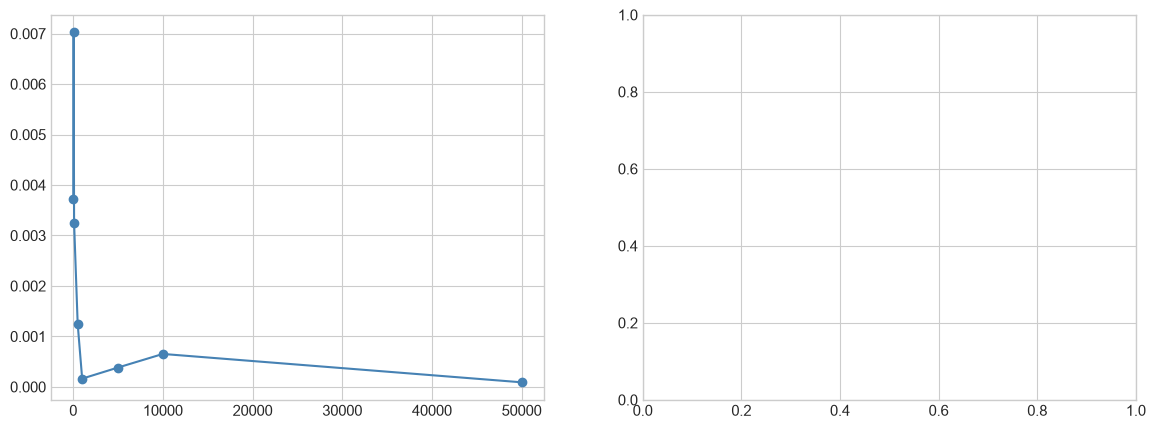

In [ ]:
# Demonstrate the 1/sqrt(n) convergence rate
n_values= np.array([10, 50, 100, 500, 1000, 5000, 10000, 50000])
n_simulations = 500

# estimate mean of exponential distribution
true_mean = 1.0
errors = []

for n in n_values:
    sample_means = [np.mean(np.random.exponential(scale=1, size=n)) for _ in range(n_simulations)]
    error = np.abs(np.mean(sample_means) - true_mean)
    errors.append(error)

errors = np.array(errors)
# plot error vs n with 1/sqrt(n) reference
fig, ax = plt.subplots(1, 2,figsize=(14, 5))

ax[0].plot(n_values, errors, marker='o', linestyle='-', color='steelblue', label='Observed Error')
theoretical_errors = errors[0]*np.sqrt(n_values[0]) /np.sqrt(n_values)
ax[0].plot(n_values, theoretical_errors,  'r--', linewidth=2, label='1/sqrt(n) Reference')
ax[0].set_xlabel('Number of Samples (n)')
ax[0].set_ylabel('Error in Mean Estimation')
ax[0].set_title('Error vs Number of Samples')
ax[0].legend()
ax[0].grid(True, alpha=0.3)

ax[1].loglog(n_values, errors, marker='o', linestyle='-', color='steelblue', label='Observed Error')
ax[1].loglog(n_values, theoretical_errors, 'r-', linewidth=2, label='1/sqrt(n) Reference')
ax[1].set_xlabel('Number of Samples (n)')   
ax[1].set_ylabel('Error in Mean Estimation')
ax[1].set_title('Error vs Number of Samples (Log-Log Scale)')
ax[1].legend()
ax[1].grid(True, alpha=0.3, which='both')

# Add slope annotation
ax[1].annotate('Slope = -0.5', xy=(1000, 0.03), fontsize=12, color='red')

plt.tight_layout()
plt.savefig('reports/error_convergence.png', dpi=150, bbox_inches='tight')
plt.show()
